In [45]:
import pandas as pd
import numpy as np
import pickle
import glob
from scipy.stats import norm
from scipy.stats import gaussian_kde
import os

# import scipy.io as sio

In [2]:
def getEnsembleMeanStd(tps, WhiteNoise, TimeHistory, TimePost = 0):
    ensemble = []
    for idx, ind in enumerate(tps):
        stimulus = WhiteNoise.values[int(ind*Fs-TimeHistory*Fs):int(ind*Fs + TimePost*Fs)]
        ensemble.append(stimulus)
        df = pd.DataFrame({'data': ensemble})

    # the columns are timepoints and rows each new Stimulus history
    expand = df.data.apply(pd.Series)
    if 660 in list(expand.columns):
        expand.drop([660],axis = 1, inplace = True)
    mean = expand.mean(axis = 0)
    std = expand.std(axis = 0)
    return(expand, mean, std)

In [43]:
# input all parameters
Fs = 3e4
TimeHistory = 20e-3 # in seconds
TimePost = 2e-3 # in seconds
Num_Repeats = 30

In [22]:
# instead of going through all data, make list of moth and unit IDs that you want to run this analysis for

moth_unit = [('m23', 'unit_1'),
             ('m29', 'unit_1'),
             ('m30', 'unit_1'),
             ('m31', 'unit_1'),
             ('m31', 'unit_2'),
             ('m31', 'unit_3')]

In [46]:
filepath_degrees = glob.glob('./dataFolder/4_RawData_Index_Timestamp/ScaledStimulus/*_degrees.pickle')
filepath_notdegrees = glob.glob('./dataFolder/4_RawData_Index_Timestamp/ScaledStimulus/*_scaled.pickle')

out_path = './dataFolder/5_1DCompModel/'
os.makedirs(out_path, exist_ok=True)

processing m23 and unit_1
unit_1 projected_prior range: -15118.1971 to 43748.6816
unit_1 projected_ste range: -15258.9223 to 44372.3434
processing m29 and unit_1
unit_1 projected_prior range: -9430.8030 to 37064.4740
unit_1 projected_ste range: -6381.3459 to 37168.7691
processing m30 and unit_1
unit_1 projected_prior range: -11621.8690 to 21740.1641
unit_1 projected_ste range: nan to nan
processing m31 and unit_1
unit_1 projected_prior range: -9193.2828 to 24143.7537
unit_1 projected_ste range: nan to nan
processing m31 and unit_2
unit_2 projected_prior range: -10754.8285 to 23010.8915
unit_2 projected_ste range: -1829.9847 to 23036.9370
processing m31 and unit_3
unit_3 projected_prior range: -9452.8366 to 25137.7797
unit_3 projected_ste range: -2708.4937 to 22731.0300


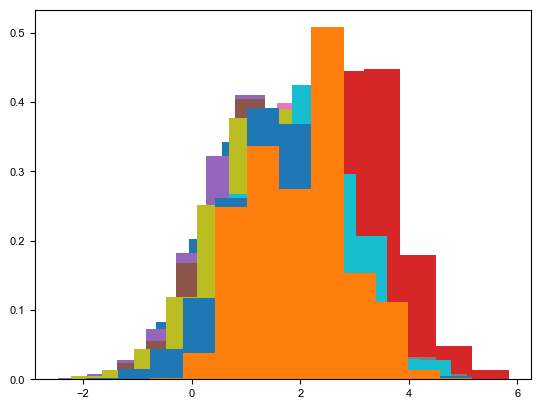

In [67]:
# read in the timestamps

for name, unitID in moth_unit:
    print(f'processing {name} and {unitID}')
    
    ########## get the correct timestamp files depending on whether we have degree or not #########################
    filename = [f for f in filepath_degrees if name in f]
    if not filename:
        filename = [f for f in filepath_notdegrees if name in f][0]
        with open(filename, "rb") as f:
            testout = pickle.load(f)
        all_Units_aligned = testout[0]
        all_Units_prior = testout[1]
        WhiteNoise = testout[2]
        
    else:
        with open(filename[0], "rb") as f:
            testout = pickle.load(f)
        all_Units_aligned = testout[0]
        all_Units_prior = testout[1]
        WhiteNoise = testout[2]
        
    ################ get STA, prior and NLD ####################################################################
    # get the ste, priors and nld
    ste = {}
    sta = {}
    sta_error = {}
    
    prior_ensemble = {}
    prior_mean = {}
    prior_error = {}
    
    nld = {}
    bins = {}
    
    for k in all_Units_aligned.keys():
        if k == unitID: # remove this is you need to run through all units. 
            
            unit_tp = np.concatenate(all_Units_aligned[k], axis = 0)
            ste[k], sta[k], sta_error[k] = getEnsembleMeanStd(unit_tp, WhiteNoise, TimeHistory, TimePost)
            
            unit_tp_prior = np.concatenate(all_Units_prior[k], axis = 0)
            prior_ensemble[k], prior_mean[k], prior_error[k] = getEnsembleMeanStd(unit_tp_prior, WhiteNoise, TimeHistory, TimePost)

            ############ NLD #####################################################################  
            num_spikeEvents = len(ste[k])
            num_priorEvents = len(prior_ensemble[k])

            sta_vec = sta[k][:-int(TimePost*Fs)]
            projected_ste = np.dot(ste[k].iloc[:,:-int(TimePost*Fs)], sta_vec) # clip the TimePost for projection analysis
            projected_prior = np.dot(prior_ensemble[k].iloc[:,:-int(TimePost*Fs)], sta_vec)
            
            print(f'{k} projected_prior range: {projected_prior.min():.4f} to {projected_prior.max():.4f}')
            print(f'{k} projected_ste range: {projected_ste.min():.4f} to {projected_ste.max():.4f}')
    
            # dividing projection bins by std of priors to normalize across neurons
            prior_std = np.std(projected_prior) # remember to save this for later predictions
            projected_ste = projected_ste / prior_std
            projected_prior = projected_prior / prior_std
    
    
            # calculate binwidth to keep it constant with respect to prior histogram
    
            sigma = np.std(projected_prior);
            bin_width = 0.3*sigma;
            num_bins = round((max(projected_prior) - min(projected_prior) / bin_width))
    
            n_prior, bin_centers, _ = plt.hist(projected_prior, bins=num_bins, density = True);
            n_ste, _, _ = plt.hist(projected_ste, bins=bin_centers, density = True);
            
            # compute rate for scaling nld from probability of firing to probability of firing rate
            Total_time_for_WN = len(WhiteNoise)*1/Fs
            Total_Time = Num_Repeats*(Total_time_for_WN)
            mean_fire_rate=len(ste[k])/Total_Time; # Scaling factor for NLD
              
            with np.errstate(invalid='ignore', divide='ignore'):
                nld = np.where(n_prior > 0, n_ste / n_prior, np.nan)
            fire_rate_nld = nld*mean_fire_rate # No longer non-dimensional         
            
            
            # save all data values
            saveObject = (ste[k], sta[k], sta_error[k], 
                          prior_ensemble[k], prior_mean[k], prior_error[k],
                          prior_std, mean_fire_rate,
                          nld, n_ste, n_prior, bin_centers)
            with open(out_path + name + '_' + unitID + "_EncodingModel.pickle","wb") as f:
                pickle.dump(saveObject, f)